# 03 · Forecasting tomorrow's covers

**Question:** how many covers will each restaurant serve tomorrow? A good forecast lets a kitchen prepare the right amount of food and schedule the right number of staff.

**Rules:**
- Only information available **the day before** is used: covers up to yesterday, the calendar, and reservations already made.
- The last **6 weeks** of data are held out for validation and never used for training.
- Every model is compared with the simple rules a restaurant manager would use.

In [1]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=RuntimeWarning)  # empty means on all-NaN windows

daily = pd.read_csv("../data/processed/daily_visits.csv", parse_dates=["visit_date"])

def clean_axes(ax, keep="bottom"):
    """Light chart style: no top/right frame, soft grid."""
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(side == keep)
    ax.spines[keep].set_color("#ccc")
    ax.tick_params(length=0, labelsize=9)

print(daily.shape)

(252108, 15)


## 3.1 Features from past covers
Covers are arranged as a restaurant × day matrix (closed days empty), so that every feature only looks at **previous** days.

In [2]:
wide = daily.pivot(index="air_store_id", columns="visit_date", values="visitors")
wide = wide.reindex(columns=pd.date_range(wide.columns.min(), wide.columns.max()))

def shifted(k):
    return wide.shift(k, axis=1)

same_dow = np.stack([shifted(k).values for k in (7, 14, 21, 28)])
past = shifted(1)

features = {
    "lag_1": shifted(1),
    "lag_7": shifted(7),
    "lag_14": shifted(14),
    "same_weekday_mean_4w": pd.DataFrame(np.nanmean(same_dow, axis=0), index=wide.index, columns=wide.columns),
    "same_weekday_max_4w": pd.DataFrame(np.nanmax(same_dow, axis=0), index=wide.index, columns=wide.columns),
    "mean_last_7d": past.T.rolling(7, min_periods=1).mean().T,
    "mean_last_28d": past.T.rolling(28, min_periods=1).mean().T,
    "open_days_last_7d": wide.notna().astype(float).shift(1, axis=1).T.rolling(7, min_periods=1).sum().T,
}

DATE_TYPE = daily["visit_date"].dtype

def to_long(frame, name):
    long = (frame.rename_axis(index="air_store_id", columns="visit_date")
                 .reset_index()
                 .melt(id_vars="air_store_id", var_name="visit_date", value_name=name))
    long["visit_date"] = pd.to_datetime(long["visit_date"]).astype(DATE_TYPE)
    return long

df = daily.copy()
for name, frame in features.items():
    df = df.merge(to_long(frame, name), on=["air_store_id", "visit_date"], how="left")
df.filter(like="_").head()

,air_store_id,visit_date,is_extreme,day_of_week,holiday_flg,air_genre_name,res_a_all,res_a_d1,res_b_all,res_b_d1,...,res_all,has_reservations,lag_1,lag_7,lag_14,same_weekday_mean_4w,same_weekday_max_4w,mean_last_7d,mean_last_28d,open_days_last_7d
0,air_ba937bf13d40fb24,2016-01-13,0,Wednesday,0,Dining bar,0.0,0.0,0.0,0.0,...,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,air_ba937bf13d40fb24,2016-01-14,0,Thursday,0,Dining bar,0.0,0.0,0.0,0.0,...,0.0,0,25.0,NaN,NaN,NaN,NaN,25.000000,25.000000,1.0
2,air_ba937bf13d40fb24,2016-01-15,0,Friday,0,Dining bar,0.0,0.0,0.0,0.0,...,0.0,0,32.0,NaN,NaN,NaN,NaN,28.500000,28.500000,2.0
3,air_ba937bf13d40fb24,2016-01-16,0,Saturday,0,Dining bar,0.0,0.0,0.0,0.0,...,0.0,0,29.0,NaN,NaN,NaN,NaN,28.666667,28.666667,3.0
4,air_ba937bf13d40fb24,2016-01-18,0,Monday,0,Dining bar,0.0,0.0,0.0,0.0,...,0.0,0,NaN,NaN,NaN,NaN,NaN,27.000000,27.000000,4.0


## 3.2 Calendar and restaurant features

In [3]:
cal = (daily[["visit_date", "holiday_flg"]].drop_duplicates()
         .set_index("visit_date").reindex(pd.date_range(daily["visit_date"].min(), daily["visit_date"].max()))
         .rename_axis("visit_date"))
cal["holiday_flg"] = cal["holiday_flg"].fillna(0)
cal["holiday_prev"] = cal["holiday_flg"].shift(1).fillna(0)
cal["holiday_next"] = cal["holiday_flg"].shift(-1).fillna(0)
cal = cal.reset_index()
cal["visit_date"] = cal["visit_date"].astype(DATE_TYPE)
df = df.merge(cal[["visit_date", "holiday_prev", "holiday_next"]], on="visit_date", how="left")

df["weekday"] = df["visit_date"].dt.dayofweek
df["month"] = df["visit_date"].dt.month
df["genre_code"] = df["air_genre_name"].astype("category").cat.codes
df["prefecture_code"] = df["prefecture"].astype("category").cat.codes

BASE = ["weekday", "month", "holiday_flg", "holiday_prev", "holiday_next", "genre_code", "prefecture_code",
        "lag_1", "lag_7", "lag_14", "same_weekday_mean_4w", "same_weekday_max_4w",
        "mean_last_7d", "mean_last_28d", "open_days_last_7d"]
RES = ["res_a_d1", "res_b_d1", "res_d1"]
CATEGORICAL = ["weekday", "genre_code", "prefecture_code"]

## 3.3 Validation split: the last 6 weeks

In [4]:
valid_start = df["visit_date"].max() - pd.Timedelta(days=41)
train = df[df["visit_date"] < valid_start]
valid = df[df["visit_date"] >= valid_start].copy()

print(f"Train: {train['visit_date'].min().date()} -> {train['visit_date'].max().date()}, {len(train):,} restaurant-days")
print(f"Valid: {valid['visit_date'].min().date()} -> {valid['visit_date'].max().date()}, {len(valid):,} restaurant-days")

Train: 2016-01-01 -> 2017-03-11, 222,073 restaurant-days
Valid: 2017-03-12 -> 2017-04-22, 30,035 restaurant-days


## 3.4 Metrics and baselines

- **WAPE** (weighted absolute percentage error) = total absolute error ÷ total covers. "10%" means that, over all restaurant-days, the forecast is off by 10 covers for every 100 served.
- **MAE**: average error in covers per restaurant-day.
- **Bias**: total forecast ÷ total actual − 1 (positive = over-forecast, i.e. food prepared and not served).
- **RMSLE**: error on the log scale, which weighs small and large restaurants more evenly.

Baselines are the rules a manager would use: *"same as last week"* and *"average of the same weekday over the last 4 weeks"*.

In [5]:
def evaluate(name, y, pred):
    pred = np.clip(pred, 0, None)
    return {
        "model": name,
        "WAPE_%": round(np.abs(pred - y).sum() / y.sum() * 100, 1),
        "MAE": round(np.abs(pred - y).mean(), 2),
        "bias_%": round((pred.sum() / y.sum() - 1) * 100, 1),
        "RMSLE": round(np.sqrt(np.mean((np.log1p(pred) - np.log1p(y)) ** 2)), 3),
    }

y = valid["visitors"].values
fallback = valid["mean_last_28d"].fillna(train["visitors"].median())
valid["pred_last_week"] = valid["lag_7"].fillna(valid["same_weekday_mean_4w"]).fillna(fallback)
valid["pred_4w_avg"] = valid["same_weekday_mean_4w"].fillna(fallback)

results = [
    evaluate("Same as last week", y, valid["pred_last_week"].values),
    evaluate("Same weekday, 4-week average", y, valid["pred_4w_avg"].values),
]
pd.DataFrame(results)

,model,WAPE_%,MAE,bias_%,RMSLE
0,Same as last week,41.9,9.25,0.1,0.675
1,"Same weekday, 4-week average",35.1,7.75,-0.2,0.567


## 3.5 Gradient boosting model
A gradient boosting model (many small decision trees, each correcting the previous ones) is trained on `log(1 + covers)`, so that small and large restaurants weigh similarly. It is trained twice: **without** and **with** online reservations, to measure what reservations add.

In [6]:
def fit_predict(cols):
    model = HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
        categorical_features=[c in CATEGORICAL for c in cols], random_state=42)
    model.fit(train[cols], np.log1p(train["visitors"]))
    return model, np.expm1(model.predict(valid[cols]))

model_base, valid["pred_model_no_res"] = fit_predict(BASE)
model_res, valid["pred_model"] = fit_predict(BASE + RES)

results.append(evaluate("Model without reservations", y, valid["pred_model_no_res"].values))
results.append(evaluate("Model with reservations", y, valid["pred_model"].values))
results_df = pd.DataFrame(results)
results_df

,model,WAPE_%,MAE,bias_%,RMSLE
0,Same as last week,41.9,9.25,0.1,0.675
1,"Same weekday, 4-week average",35.1,7.75,-0.2,0.567
2,Model without reservations,33.0,7.28,-10.8,0.515
3,Model with reservations,31.8,7.02,-8.9,0.503


In [7]:
mask = valid["has_reservations"] == 1
sub = pd.DataFrame([
    evaluate("Without reservations", y[mask.values], valid.loc[mask, "pred_model_no_res"].values),
    evaluate("With reservations", y[mask.values], valid.loc[mask, "pred_model"].values),
])
print(f"Restaurants with reservation data only ({mask.sum():,} restaurant-days):")
sub

Restaurants with reservation data only (12,403 restaurant-days):


,model,WAPE_%,MAE,bias_%,RMSLE
0,Without reservations,35.0,8.46,-12.1,0.546
1,With reservations,32.2,7.77,-6.8,0.517


- The model reduces the error from **35.1%** (best baseline) to **31.8%** WAPE, and from **41.9%** compared with "same as last week" (−24%).
- Reservations help: WAPE 33.0% → 31.8% overall, and 35.0% → 32.2% for restaurants with reservation data.
- **Bias:** the model under-forecasts by ~9%. It is trained on log(1 + covers), so its predictions sit closer to a typical day than to the average day, which is pulled up by busy days. A scaling correction or a Poisson loss would remove this; here the bias is kept visible and its effect is measured in notebook 04.

## 3.6 Model comparison

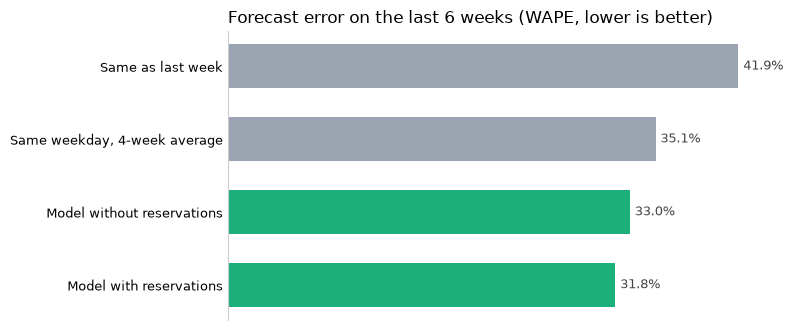

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.4))
r = results_df.iloc[::-1]
colors = ["#1baf7a" if "Model" in m else "#9aa5b1" for m in r["model"]]
ax.barh(r["model"], r["WAPE_%"], color=colors, height=0.6)
for i, v in enumerate(r["WAPE_%"]):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=9, color="#444")
clean_axes(ax, keep="left")
ax.xaxis.set_visible(False)
ax.set_title("Forecast error on the last 6 weeks (WAPE, lower is better)", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.7 One restaurant, day by day

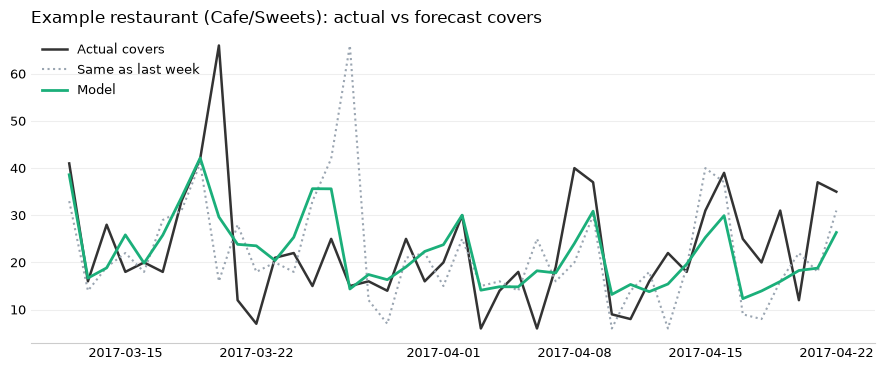

In [9]:
counts = valid[valid["has_reservations"] == 1].groupby("air_store_id").size()
example = counts.idxmax() if len(counts) else valid["air_store_id"].value_counts().idxmax()
ex = valid[valid["air_store_id"] == example].sort_values("visit_date")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(ex["visit_date"], ex["visitors"], color="#333", linewidth=1.8, label="Actual covers")
ax.plot(ex["visit_date"], ex["pred_last_week"], color="#9aa5b1", linewidth=1.5, linestyle=":", label="Same as last week")
ax.plot(ex["visit_date"], ex["pred_model"], color="#1baf7a", linewidth=2, label="Model")
clean_axes(ax)
ax.grid(axis="y", color="#eee", linewidth=0.8)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title(f"Example restaurant ({ex['air_genre_name'].iloc[0]}): actual vs forecast covers", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/example_restaurant.png", dpi=150, bbox_inches="tight")
plt.show()

## 3.8 What drives the forecast?

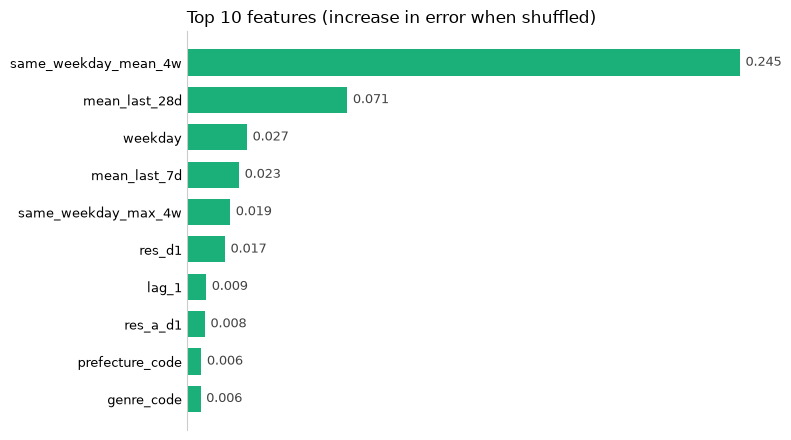

In [10]:
sample = valid.sample(min(20000, len(valid)), random_state=42)
cols = BASE + RES
imp = permutation_importance(model_res, sample[cols], np.log1p(sample["visitors"]),
                             scoring="neg_mean_squared_error", n_repeats=3, random_state=42)
importance = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 4.5))
s = importance.sort_values()
ax.barh(s.index, s.values, color="#1baf7a", height=0.7)
for i, v in enumerate(s.values):
    ax.text(v + s.max() * 0.01, i, f"{v:.3f}", va="center", fontsize=9, color="#444")
clean_axes(ax, keep="left")
ax.xaxis.set_visible(False)
ax.set_title("Top 10 features (increase in error when shuffled)", loc="left", fontsize=12)
plt.tight_layout()
plt.savefig("../figures/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
keep = ["air_store_id", "visit_date", "visitors", "day_of_week", "holiday_flg", "air_genre_name",
        "has_reservations", "res_d1", "is_extreme", "pred_last_week", "pred_4w_avg", "pred_model_no_res", "pred_model"]
valid[keep].to_csv("../data/processed/validation_predictions.csv", index=False)
print(valid[keep].shape)

(30035, 13)


## Summary

In [12]:
best_base = results_df.iloc[:2].sort_values("WAPE_%").iloc[0]
final = results_df.set_index("model").loc["Model with reservations"]
no_res = results_df.set_index("model").loc["Model without reservations"]
print(results_df.to_string(index=False))
print()
print(f"Best baseline: {best_base['model']} (WAPE {best_base['WAPE_%']}%)")
print(f"Final model: WAPE {final['WAPE_%']}%, MAE {final['MAE']} covers, bias {final['bias_%']}%, RMSLE {final['RMSLE']}")
print(f"Error reduction vs best baseline: {(1 - final['WAPE_%'] / best_base['WAPE_%']) * 100:.1f}%")
print(f"Reservations: WAPE {no_res['WAPE_%']}% -> {final['WAPE_%']}% (all restaurants); "
      f"{sub.iloc[0]['WAPE_%']}% -> {sub.iloc[1]['WAPE_%']}% (restaurants with reservation data)")
print("Top 5 features:", ", ".join(importance.index[:5]))

                       model  WAPE_%  MAE  bias_%  RMSLE
           Same as last week    41.9 9.25     0.1  0.675
Same weekday, 4-week average    35.1 7.75    -0.2  0.567
  Model without reservations    33.0 7.28   -10.8  0.515
     Model with reservations    31.8 7.02    -8.9  0.503

Best baseline: Same weekday, 4-week average (WAPE 35.1%)
Final model: WAPE 31.8%, MAE 7.02 covers, bias -8.9%, RMSLE 0.503
Error reduction vs best baseline: 9.4%
Reservations: WAPE 33.0% -> 31.8% (all restaurants); 35.0% -> 32.2% (restaurants with reservation data)
Top 5 features: same_weekday_mean_4w, mean_last_28d, weekday, mean_last_7d, same_weekday_max_4w


## Findings

1. **Simple rules are hard to beat by much, but they can be beaten.** "Same weekday, 4-week average" (35.1% WAPE) is already far better than "same as last week" (41.9%). The model brings the error to 31.8%: −9.4% vs the best rule, −24% vs "last week".
2. **Recent history drives the forecast.** The top features are the 4-week same-weekday average, the 28-day and 7-day averages, the weekday and the 4-week same-weekday maximum.
3. **Reservations add value where they exist:** −2.8 points of WAPE for restaurants with online bookings.
4. **The model is cautious:** it under-forecasts total covers by 8.9%, a known effect of training on the log scale.

**Final model:** gradient boosting with reservations: WAPE 31.8%, MAE 7.02 covers per restaurant-day, bias −8.9%, RMSLE 0.503 on the last 6 weeks.